In [9]:
from OptimizationModel_testing import opmiziation_modeling_testing
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import os
from pathlib import Path

# make sure to save csv at output folder
if Path.cwd().name == "code":
    os.chdir(Path.cwd().parent)

capacity_base = [60, 80, 100, 120, 140, 160, 180, 200, 220, 250]

test_cases = [
    {"name": "slots_22",    "slots": 22, "capacity_rate": 1.00},
    {"name": "slots_23",    "slots": 23, "capacity_rate": 1.00},
  {"name": "slots_24(base)","slots": 24, "capacity_rate": 1.00},
    {"name": "slots_25",    "slots": 25, "capacity_rate": 1.00},
    {"name": "slots_26",    "slots": 26, "capacity_rate": 1.00},
    {"name": "capacity_80", "slots": 24, "capacity_rate": 0.80},
    {"name": "capacity_60", "slots": 24, "capacity_rate": 0.60},
    {"name": "capacity_40", "slots": 24, "capacity_rate": 0.40},
    {"name": "capacity_30", "slots": 24, "capacity_rate": 0.30},
    {"name": "capacity_25", "slots": 24, "capacity_rate": 0.25},
    {"name": "capacity_20", "slots": 24, "capacity_rate": 0.20},
]

status_names = {
    GRB.OPTIMAL: "OPTIMAL",
    GRB.INFEASIBLE: "INFEASIBLE",
    GRB.TIME_LIMIT: "TIME_LIMIT",
    GRB.INTERRUPTED: "INTERRUPTED",
}

test_results = []

for case in test_cases:
    # rounding
    capacity = [ int(round(seats * case["capacity_rate"], 0)) for seats in capacity_base ]
    csv_name = f"{case['name']}_schedule.csv"

    print(f"\n===== {case['name']} =====")

    result = opmiziation_modeling_testing(
        slots=case["slots"],
        capacity=capacity,
        csv_name=csv_name,
    )

    # feasibility 
    if result["has_solution"]:
        feasibility = "Feasible"
    elif result["status"] == GRB.INFEASIBLE:
        feasibility = "Infeasible"
    else:
        break

    # save each result
    test_results.append({
        "test_name": case["name"],
        "slots": result["slots"],
        "capacity_percent": case["capacity_rate"] * 100,
        "status": status_names.get(result["status"], str(result["status"])),
        "feasibility": feasibility,
        "runtime_seconds": result["runtime"],
        "schedule_file": csv_name if result["has_solution"] else None,
    })

# save the results to csv
test_results_df = pd.DataFrame(test_results)
test_results_df.to_csv("outputs/test_results.csv", index=False)

display(test_results_df)


===== slots_22 =====
--- Data Simulation Complete ---
Courses: 25 | Rooms: 10 | Time Slots: 22 | Students: 400
Set parameter LogToConsole to value 0
Building student conflict constraints...
Optimizing model with Gurobi...

Optimization finished with status 3.

===== slots_23 =====
--- Data Simulation Complete ---
Courses: 25 | Rooms: 10 | Time Slots: 23 | Students: 400
Set parameter LogToConsole to value 0
Building student conflict constraints...
Optimizing model with Gurobi...

Optimization finished with status 3.

===== slots_24(base) =====
--- Data Simulation Complete ---
Courses: 25 | Rooms: 10 | Time Slots: 24 | Students: 400
Set parameter LogToConsole to value 0
Building student conflict constraints...
Optimizing model with Gurobi...

Model solved successfully to OPTIMAL status!
Optimal exam schedule exported to 'outputs/slots_24(base)_schedule.csv'!
   Course  Enrollment Assigned_Room  Room_Capacity Time_Slot  Day
0  CS_100          61      Room_105            140   Slot_12    

,test_name,slots,capacity_percent,status,feasibility,runtime_seconds,schedule_file
0,slots_22,22,100.0,INFEASIBLE,Infeasible,0.416,None
1,slots_23,23,100.0,INFEASIBLE,Infeasible,0.338,None
2,slots_24(base),24,100.0,OPTIMAL,Feasible,0.011,slots_24(base)_schedule.csv
3,slots_25,25,100.0,OPTIMAL,Feasible,0.011,slots_25_schedule.csv
4,slots_26,26,100.0,OPTIMAL,Feasible,0.009,slots_26_schedule.csv
5,capacity_80,24,80.0,OPTIMAL,Feasible,0.035,capacity_80_schedule.csv
6,capacity_60,24,60.0,OPTIMAL,Feasible,0.013,capacity_60_schedule.csv
7,capacity_40,24,40.0,OPTIMAL,Feasible,0.002,capacity_40_schedule.csv
8,capacity_30,24,30.0,OPTIMAL,Feasible,0.003,capacity_30_schedule.csv
9,capacity_25,24,25.0,INFEASIBLE,Infeasible,0.084,None


In [10]:
# separate results by parameter
slot_results = test_results_df[test_results_df["capacity_percent"] == 100]
capacity_results = test_results_df[test_results_df["slots"] == 24]

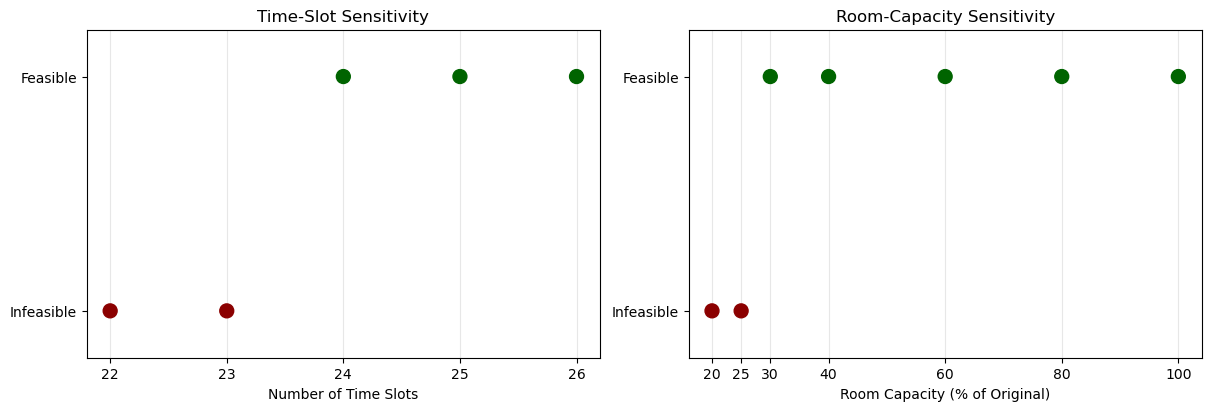

In [ ]:
import matplotlib.pyplot as plt

feasb_num = {"Infeasible": 0, "Feasible": 1}
feasb_color = {"Infeasible": "darkred", "Feasible": "darkgreen"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
# feasibility based on the number of available time slots.
axes[0].scatter(
    slot_results["slots"],
    slot_results["feasibility"].map(feasb_num),
    c=slot_results["feasibility"].map(feasb_color),
    s=100,
)
axes[0].set_title("Time-Slot Sensitivity")
axes[0].set_xlabel("Number of Time Slots")
axes[0].set_xticks(slot_results["slots"])

# feasibility based on the room-capacity percentage.
axes[1].scatter(
    capacity_results["capacity_percent"],
    capacity_results["feasibility"].map(feasb_num),
    c=capacity_results["feasibility"].map(feasb_color),
    s=100,
)
axes[1].set_title("Room-Capacity Sensitivity")
axes[1].set_xlabel("Room Capacity (% of Original)")
axes[1].set_xticks(capacity_results["capacity_percent"])

# feasibility scale on both
for ax in axes:
    ax.set_yticks([0, 1], ["Infeasible", "Feasible"])
    ax.set_ylim(-0.2, 1.2)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.3)

plt.show()

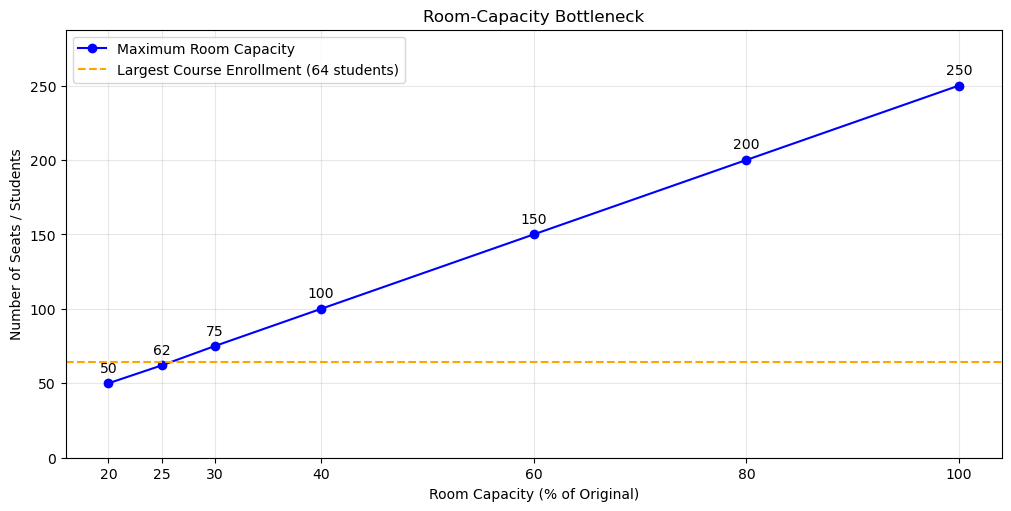

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# largest course enrollment in the baseline schedule.
base_df = pd.read_csv("outputs/slots_24(base)_schedule.csv")
max_course = base_df["Enrollment"].max()

# select capacity experiments while keeping 24 time slots fixed.
max_df = (test_results_df.loc[test_results_df["slots"] == 24, 
                                     ["capacity_percent", "feasibility"],].sort_values("capacity_percent").copy())

# the same capacity-rounding rule used in the test loop.
max_df["max_room_capacity"] = [int(round(max(capacity_base) * percent / 100)) 
                                      for percent in max_df["capacity_percent"]]

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

# the largest available room capacity for each case.
ax.plot(
    max_df["capacity_percent"],
    max_df["max_room_capacity"],
    marker="o",
    color="blue",
    label="Maximum Room Capacity",
)

# border line
ax.axhline(
    max_course,
    color="orange",
    linestyle="--",
    label=f"Largest Course Enrollment ({max_course} students)",
)

# label each tested room capacity.
for percent, seats in zip(
    max_df["capacity_percent"],
    max_df["max_room_capacity"],
):
    ax.annotate(
        str(seats),
        (percent, seats),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
    )

ax.set_title("Room-Capacity Bottleneck")
ax.set_xlabel("Room Capacity (% of Original)")
ax.set_ylabel("Number of Seats / Students")
ax.set_xticks(max_df["capacity_percent"])
ax.set_ylim(0, max_df["max_room_capacity"].max() * 1.15)
ax.grid(alpha=0.3)
ax.legend()

plt.show()